In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from skbio.stats.composition import clr as skbio_clr

warnings.filterwarnings("ignore")

# ── 1. Paths ──────────────────────────────────────────────────────────────────
TAX_PATH      = '/srv/common/microbime_data/tax.csv'
PATH_PATH     = '/srv/common/microbime_data/path.csv'
METADATA_PATH = '/srv/common/microbime_data/metadata.csv'
OUTPUT_DIR    = './output_loso'

# ── 2. Settings ───────────────────────────────────────────────────────────────
INNER_FOLDS     = 3
RANDOM_STATE    = 42
CLR_PSEUDO      = 1e-6
MIN_PREVALENCE  = 0.10
MIN_BIOPROJECTS = 3

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── 3. Configs ────────────────────────────────────────────────────────────────
CONFIGS = [
    # K05 — Periodontitis
    {"task": "K05", "feature_set": "TAX",      "transform": "CLR",      "model": "LR_Ridge"},
    {"task": "K05", "feature_set": "TAX+PATH", "transform": "CLR",      "model": "LR_Ridge"},
    {"task": "K05", "feature_set": "PATH",     "transform": "CLR",      "model": "LR_Ridge"},
    # K02 — Caries
    {"task": "K02", "feature_set": "TAX",      "transform": "rank.std", "model": "XGBoost"},
    {"task": "K02", "feature_set": "TAX+PATH", "transform": "CLR",      "model": "RF"},
    {"task": "K02", "feature_set": "PATH",     "transform": "CLR",      "model": "RF"},
]

# ── 4. Hyperparameter grids ───────────────────────────────────────────────────
PARAM_GRIDS = {
    "LR_Ridge": {"C": [0.001, 0.01, 0.1, 1, 10, 100]},
    "XGBoost": {
        "n_estimators":     [100, 300],
        "max_depth":        [3, 5],
        "learning_rate":    [0.01, 0.1],
        "subsample":        [0.7, 1.0],
        "colsample_bytree": [0.7, 1.0],
    },
    "RF": {
        "n_estimators": [100, 300, 500],
        "max_depth":    [None, 5, 10],
        "max_features": ["sqrt", 0.3],
    },
}

In [2]:
# ── 5. Transforms ─────────────────────────────────────────────────────────────
def apply_clr(X):
    return skbio_clr(X + CLR_PSEUDO)

def to_relative(X):
    row_sums = X.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return X / row_sums

def apply_clr_blocks(X, n_tax):
    return np.concatenate([apply_clr(X[:, :n_tax]), apply_clr(to_relative(X[:, n_tax:]))], axis=1)

def rank_std_fit(X_train):
    ranked = np.apply_along_axis(lambda row: row.argsort().argsort().astype(float), axis=1, arr=X_train)
    mu  = ranked.mean(axis=0)
    std = ranked.std(axis=0)
    std[std == 0] = 1.0
    return mu, std

def rank_std_transform(X, mu, std):
    ranked = np.apply_along_axis(lambda row: row.argsort().argsort().astype(float), axis=1, arr=X)
    return (ranked - mu) / std

def transform_fold(X_tr, X_te, transform_name, feature_set, n_tax):
    if transform_name == "CLR":
        if feature_set == "TAX+PATH":
            return apply_clr_blocks(X_tr, n_tax), apply_clr_blocks(X_te, n_tax)
        elif feature_set == "PATH":
            return apply_clr(to_relative(X_tr)), apply_clr(to_relative(X_te))
        else:
            return apply_clr(X_tr), apply_clr(X_te)
    if transform_name == "rank.std":
        mu, std = rank_std_fit(X_tr)
        return rank_std_transform(X_tr, mu, std), rank_std_transform(X_te, mu, std)
    raise ValueError(f"Unknown transform: {transform_name}")

# ── 6. Model factory ──────────────────────────────────────────────────────────
def get_model(model_name):
    if model_name == "LR_Ridge":
        return LogisticRegression(penalty="l2", solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)
    if model_name == "XGBoost":
        return XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, verbosity=0, n_jobs=-1)
    if model_name == "RF":
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    raise ValueError(f"Unknown model: {model_name}")

# ── 7. Inner tuning + predict ─────────────────────────────────────────────────
def tune_and_predict(X_tr, y_tr, X_te, model_name):
    if len(np.unique(y_tr)) < 2:
        print("      [WARN] only 1 class in train — returning 0.5")
        return np.full(len(X_te), 0.5)
    model = get_model(model_name)
    grid  = PARAM_GRIDS.get(model_name, {})
    n_pos, n_neg = int(y_tr.sum()), int((y_tr == 0).sum())
    if grid and n_pos >= INNER_FOLDS and n_neg >= INNER_FOLDS:
        inner_cv = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        gs = GridSearchCV(model, grid, cv=inner_cv, scoring="roc_auc", refit=True, n_jobs=-1)
        gs.fit(X_tr, y_tr)
        print(f"      best params: {gs.best_params_}  inner AUC={gs.best_score_:.4f}")
        return gs.best_estimator_.predict_proba(X_te)[:, 1]
    else:
        print(f"      [WARN] inner CV skipped (n_pos={n_pos}, n_neg={n_neg}) — using defaults")
        model.fit(X_tr, y_tr)
        return model.predict_proba(X_te)[:, 1]

# ── 8. Feature filtering function ────────────────────────────────────────────
def prevalence_bioproject_filter(X, feature_names, bioproject, label):
    present    = X > 0
    prevalence = present.mean(axis=0)
    n_bp = np.array([len(np.unique(bioproject[present[:, j]])) if present[:, j].any() else 0 for j in range(X.shape[1])])
    keep = (prevalence >= MIN_PREVALENCE) & (n_bp >= MIN_BIOPROJECTS)
    kept_names = [feature_names[i] for i in range(len(feature_names)) if keep[i]]
    print(f"  {label}: {X.shape[1]} → {keep.sum()} features kept (removed {(~keep).sum()})")
    return X[:, keep], kept_names

In [3]:
# ── 9. Load data ──────────────────────────────────────────────────────────────
print("Loading data...")
meta = pd.read_csv(METADATA_PATH)
tax  = pd.read_csv(TAX_PATH)
path = pd.read_csv(PATH_PATH)

df = meta.merge(tax, on="run").merge(path, on="run")

tax_cols  = [c for c in tax.columns  if c != "run"]
path_cols = [c for c in path.columns if c != "run"]

X_tax  = df[tax_cols].values.astype(float)
X_path = df[path_cols].values.astype(float)

y_k05      = df["K05_gingivitis_periodontitis"].values.astype(int)
y_k02      = df["K02_caries"].values.astype(int)
healthy    = df["healthy"].values.astype(bool)
bioproject = df["bioproject"].values.astype(str)

print(f"Total: {len(df)}  K05=1: {y_k05.sum()}  K02=1: {y_k02.sum()}  healthy: {healthy.sum()}")

# ── 10. Feature filtering ─────────────────────────────────────────────────────
print("\nFeature filtering...")
X_tax_f,  tax_cols_f  = prevalence_bioproject_filter(X_tax,  tax_cols,  bioproject, "TAX")
X_path_f, path_cols_f = prevalence_bioproject_filter(X_path, path_cols, bioproject, "PATH")
X_both_f  = np.concatenate([X_tax_f, X_path_f], axis=1)
n_tax     = X_tax_f.shape[1]

feature_sets = {"TAX": X_tax_f, "PATH": X_path_f, "TAX+PATH": X_both_f}
print(f"TAX: {X_tax_f.shape[1]}  PATH: {X_path_f.shape[1]}  TAX+PATH: {X_both_f.shape[1]}")

Loading data...
Total: 558  K05=1: 161  K02=1: 205  healthy: 223

Feature filtering...
  TAX: 719 → 366 features kept (removed 353)
  PATH: 522 → 337 features kept (removed 185)
TAX: 366  PATH: 337  TAX+PATH: 703


In [4]:
# ── 11. Планирование LOSO-фолдов заранее ─────────────────────────────────────
# Для каждой задачи и каждого биопроекта определяем:
#   "test"       — есть оба класса (disease + не-disease) → можно считать AUC
#   "train_only" — только один класс → участвует только в трейне других фолдов

def plan_loso(y, bioproject, task_name):
    plan = {}
    for bp in sorted(np.unique(bioproject)):
        mask = bioproject == bp
        plan[bp] = "test" if len(np.unique(y[mask])) == 2 else "train_only"

    test_bps       = [bp for bp, role in plan.items() if role == "test"]
    train_only_bps = [bp for bp, role in plan.items() if role == "train_only"]

    # детальная таблица по каждому биопроекту
    rows = []
    for bp, role in plan.items():
        mask = bioproject == bp
        rows.append({
            "bioproject":  bp,
            "n_total":     int(mask.sum()),
            "n_disease":   int(y[mask].sum()),
            "n_other":     int((y[mask] == 0).sum()),
            "role":        role,
        })
    plan_df = pd.DataFrame(rows)

    print(f"\n  {task_name}:")
    print(plan_df.to_string(index=False))
    print(f"\n  → в тест пойдут ({len(test_bps)}): {test_bps}")
    print(f"  → только трейн  ({len(train_only_bps)}): {train_only_bps}")
    return plan

print("\n── LOSO план ────────────────────────────────────────────────────────────────")
loso_plan = {
    "K05": plan_loso(y_k05, bioproject, "K05 Periodontitis"),
    "K02": plan_loso(y_k02, bioproject, "K02 Caries"),
}


── LOSO план ────────────────────────────────────────────────────────────────

  K05 Periodontitis:
  bioproject  n_total  n_disease  n_other       role
  PRJEB36291       20          0       20 train_only
  PRJEB42701       15         15        0 train_only
PRJNA1057503      193         87      106       test
PRJNA1162519        3          3        0 train_only
PRJNA1379526       11          0       11 train_only
 PRJNA380711       88          0       88 train_only
 PRJNA396840       30         10       20       test
 PRJNA478018       45          0       45 train_only
 PRJNA678453       22         11       11       test
 PRJNA717815       26         14       12       test
 PRJNA741688       18         12        6       test
 PRJNA752888       30          0       30 train_only
 PRJNA929548       37          0       37 train_only
 PRJNA932553       20          9       11       test

  → в тест пойдут (6): [np.str_('PRJNA1057503'), np.str_('PRJNA396840'), np.str_('PRJNA678453'), np.str

In [ ]:
# ── 12. LOSO loop ─────────────────────────────────────────────────────────────
loso_results = {}

for cfg in CONFIGS:
    task        = cfg["task"]
    feature_set = cfg["feature_set"]
    transform   = cfg["transform"]
    model_name  = cfg["model"]
    cfg_name    = f"{feature_set} | {transform} | {model_name}"

    print(f"\n{'='*65}")
    print(f"Config: {task} | {cfg_name}")

    y          = y_k05 if task == "K05" else y_k02
    is_disease = y.astype(bool)
    X_raw      = feature_sets[feature_set]
    plan       = loso_plan[task]
    test_bps   = [bp for bp, role in plan.items() if role == "test"]

    print(f"  Тестовых фолдов: {len(test_bps)}")
    loso_results.setdefault(task, {})[cfg_name] = {}

    for test_bp in test_bps:
        test_mask  = bioproject == test_bp
        train_mask = (~test_mask) & (is_disease | healthy)

        X_tr_raw, X_te_raw = X_raw[train_mask], X_raw[test_mask]
        y_tr, y_te = y[train_mask], y[test_mask]

        print(f"\n  Test: {test_bp}  n_test={len(y_te)} (pos={int(y_te.sum())})  n_train={len(y_tr)} (pos={int(y_tr.sum())})")

        X_tr_t, X_te_t = transform_fold(X_tr_raw, X_te_raw, transform, feature_set, n_tax)
        probs = tune_and_predict(X_tr_t, y_tr, X_te_t, model_name)
        auc   = roc_auc_score(y_te, probs)
        loso_results[task][cfg_name][test_bp] = round(auc, 4)
        print(f"      AUC = {auc:.4f}")


──────────────────────────────────────────────────────────────────────
  K05 Periodontitis
──────────────────────────────────────────────────────────────────────
                           PRJNA1057503  PRJNA396840  PRJNA678453  PRJNA717815  PRJNA741688  PRJNA932553  mean_AUC  std_AUC
TAX | CLR | LR_Ridge             0.6193        0.865       0.9339       0.9583       0.7500       0.8788    0.8342   0.1277
TAX+PATH | CLR | LR_Ridge        0.6092        0.900       0.8926       0.9464       0.7639       0.8889    0.8335   0.1256
PATH | CLR | LR_Ridge            0.5640        0.695       0.8760       0.7857       0.7361       0.7273    0.7307   0.1032
Saved → ./output_loso/loso_K05.csv
Heatmap saved → ./output_loso/loso_heatmap_K05.png


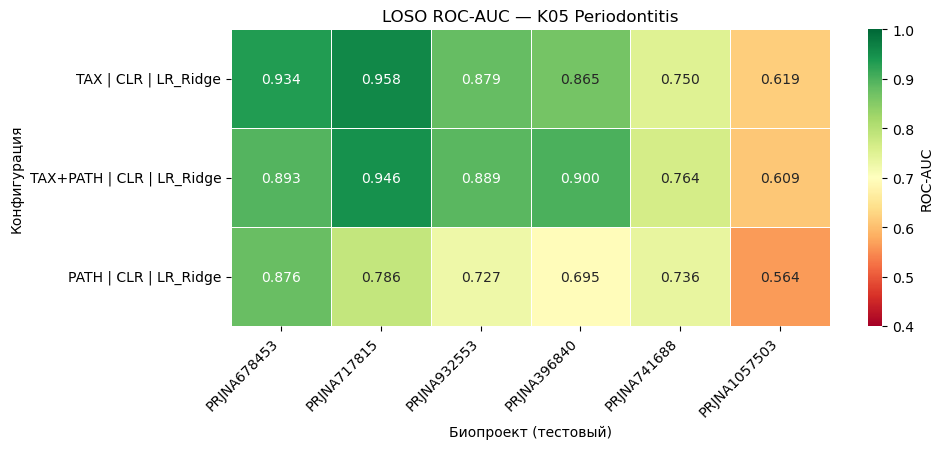


──────────────────────────────────────────────────────────────────────
  K02 Caries
──────────────────────────────────────────────────────────────────────
                          PRJNA1057503  PRJNA380711  PRJNA396840  PRJNA478018  PRJNA752888  PRJNA929548  mean_AUC  std_AUC
TAX | rank.std | XGBoost        0.6057       0.6558       0.8150       0.6719       0.6844       0.6955    0.6881   0.0697
TAX+PATH | CLR | RF             0.6249       0.6653       0.7400       0.6660       0.5333       0.8622    0.6819   0.1111
PATH | CLR | RF                 0.5393       0.4326       0.5875       0.5435       0.5378       0.7885    0.5715   0.1180
Saved → ./output_loso/loso_K02.csv
Heatmap saved → ./output_loso/loso_heatmap_K02.png


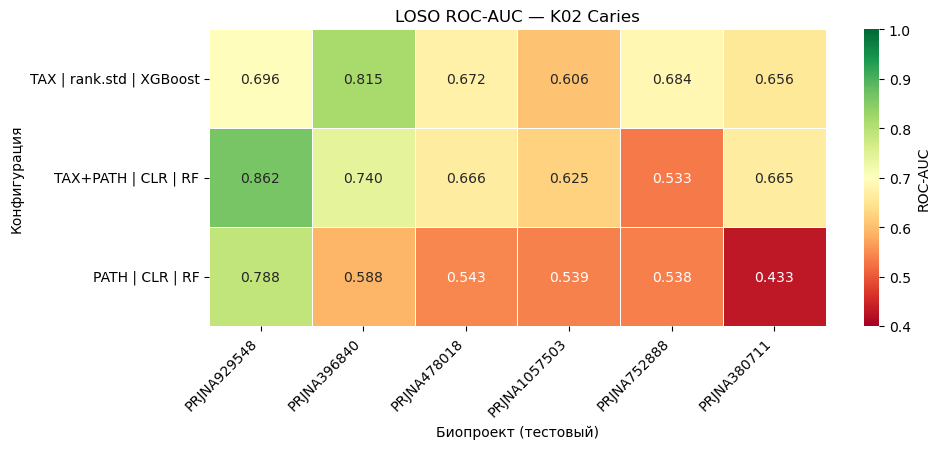

In [8]:
# ── 13. Summary table + heatmap ───────────────────────────────────────────────
for task in ["K05", "K02"]:
    task_label = "K05 Periodontitis" if task == "K05" else "K02 Caries"

    print(f"\n{'─'*70}\n  {task_label}\n{'─'*70}")
    df_task = pd.DataFrame(loso_results[task]).T
    df_task["mean_AUC"] = df_task.mean(axis=1, skipna=True).round(4)
    df_task["std_AUC"]  = df_task.drop(columns="mean_AUC").std(axis=1, skipna=True).round(4)
    print(df_task.to_string())
    df_task.to_csv(os.path.join(OUTPUT_DIR, f"loso_{task}.csv"))
    print(f"Saved → {OUTPUT_DIR}/loso_{task}.csv")

    # heatmap — только информативные столбцы (plan гарантирует оба класса)
    df_heat  = pd.DataFrame(loso_results[task]).T
    col_order = df_heat.mean(axis=0, skipna=True).sort_values(ascending=False).index
    df_heat  = df_heat[col_order]
    mean_col = df_heat.mean(axis=1, skipna=True).round(3)

    fig, ax = plt.subplots(figsize=(max(10, len(df_heat.columns) * 1.1), len(df_heat) * 1.2 + 1))
    sns.heatmap(df_heat.astype(float), ax=ax, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.4, vmax=1.0, linewidths=0.5, linecolor="white", cbar_kws={"label": "ROC-AUC"})


    ax.set_title(f"LOSO ROC-AUC — {task_label}", fontsize=12)
    ax.set_xlabel("Биопроект (тестовый)")
    ax.set_ylabel("Конфигурация")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()

    plot_path = os.path.join(OUTPUT_DIR, f"loso_heatmap_{task}.png")
    fig.savefig(plot_path, dpi=150, bbox_inches="tight")
    print(f"Heatmap saved → {plot_path}")
    plt.show()